# 🎬 Hệ Thống Gợi Ý Phim Hybrid AI (MovieLens 32M)
### Kết hợp Collaborative Filtering (CF) & Machine Learning (LightGBM Ranker)

**Quy mô dữ liệu:**
- **32,000,204** lượt đánh giá (ratings) từ **200,948** người dùng trên **87,585** bộ phim.
- Hơn **2,000,000** lượt gán thẻ nội dung (tags).

**Kiến trúc 2 vòng chuẩn công nghiệp (Two-Stage Recommendation Pipeline):**
1. **Giai đoạn 1 (Phase 1):** Chuẩn bị & Chế biến dữ liệu (Data Preprocessing & Feature Engineering).
2. **Giai đoạn 2 (Phase 2):** Lọc nhanh ứng viên (Candidate Retrieval via Collaborative Filtering - Top 300).
3. **Giai đoạn 3 (Phase 3):** Chấm điểm & Xếp hạng chi tiết (Scoring & Re-ranking via LightGBM Classifier/Ranker).
4. **Giai đoạn 4 (Phase 4):** Pipeline gợi ý hoàn chỉnh & Đánh giá kết quả (Top 10 Recommendation Demo).

## 🛠️ Bước 0: Cài đặt thư viện & Chuẩn bị môi trường

In [1]:
# Cài đặt các thư viện cần thiết trên Colab nếu chưa có
!pip install -q lightgbm scikit-learn pandas numpy scipy

import os
import re
import zipfile
import urllib.request
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

DATA_DIR = './data'
ZIP_PATH = './ml-32m.zip'
os.makedirs(DATA_DIR, exist_ok=True)

# Tự động tải dữ liệu MovieLens 32M nếu chạy trên môi trường mới
if not os.path.exists(ZIP_PATH):
    print('Đang tải MovieLens 32M (238 MB)...')
    url = 'https://files.grouplens.org/datasets/movielens/ml-32m.zip'
    urllib.request.urlretrieve(url, ZIP_PATH)
    print('✅ Tải dữ liệu hoàn tất!')
else:
    print(f'✅ Đã tìm thấy tệp dữ liệu: {ZIP_PATH}')

Đang tải MovieLens 32M (238 MB)...
✅ Tải dữ liệu hoàn tất!


## 🚀 GIAI ĐOẠN 1: Chuẩn Bị & Chế Biến Dữ Liệu (Feature Engineering)

Giai đoạn này giải quyết 4 nhiệm vụ cốt lõi:
1. **Xử lý phim (`movies.csv`):** Tách năm phát hành (`release_year`), tính tuổi phim (`movie_age`), và mã hóa 18 thể loại (`genre_*`).
2. **Khai phá thẻ (`tags.csv`):** Sử dụng thuật toán TF-IDF trích xuất 30 đặc trưng phong cách nội dung (twist ending, atmospheric, sci-fi...).
3. **Thống kê toàn cục (`ratings.csv`):** Quét toàn bộ 32M dòng bằng kỹ thuật chunking để đo độ phổ biến và điểm trung bình.
4. **Gán nhãn giám sát & Chia tập theo thời gian:** $y = 1$ (Thích nếu rating $\ge 4.0$) và chia 80% quá khứ để Train, 20% gần đây để Test.

### 1.1 & 1.2: Xử lý thông tin phim & Mã hóa thể loại, tags

In [2]:
print('1. Đang đọc và làm sạch movies.csv...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    with z.open('ml-32m/movies.csv') as f:
        df_movies = pd.read_csv(f)

print(f'Tổng số phim ban đầu: {len(df_movies):,}')

1. Đang đọc và làm sạch movies.csv...
Tổng số phim ban đầu: 87,585


In [3]:
df_movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Thêm feature year (tách từ feature title ra) : có 2 cách
- 1 là viêt function extract_year(title)
- 2 là viết trên cùng một hàm -> cách này sẽ tối ưu tốc độ trên Pandas

In [4]:
# cách 1
# Trích xuất năm phát hành từ title
def extract_year(title):
    match = re.search(r'\((\d{4})\)', str(title))
    return int(match.group(1)) if match else np.nan

df_movies['release_year'] = df_movies['title'].apply(extract_year)


df_movies.head()

,movieId,title,genres,release_year
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II (1995),Comedy,1995.0


In [5]:
# cách 2
df_movies['release_year'] = df_movies['title'].str.extract(r'\((\d{4})\)').astype(float)

df_movies.head()

,movieId,title,genres,release_year
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II (1995),Comedy,1995.0


kiểm tra xem là trong release_year nó có các ô bị nan hay không , nếu có thì đi chuẩn hóa

In [6]:
df_movies[df_movies["release_year"].isna()]

,movieId,title,genres,release_year
15038,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller,NaN
25425,123619,Terrible Joe Moran,(no genres listed),NaN
26356,125571,The Court-Martial of Jackie Robinson,(no genres listed),NaN
26381,125632,In Our Garden,(no genres listed),NaN
26466,125958,Stephen Fry In America - New World,(no genres listed),NaN
...,...,...,...,...
86528,288927,Fortunes,Comedy,NaN
86634,289193,The Wonderful Story of Henry Sugar,Adventure|Children|Comedy,NaN
86833,289909,Rattler,(no genres listed),NaN
87074,290775,Being Romanian: A Family Journal,(no genres listed),NaN


### 🌟 Chiến lược điền khuyết năm phát hành (release_year) 3 Tầng:

- **Tầng 1 (Chính xác nhất - Đã thực hiện):** Lấy năm trích xuất trực tiếp từ `title` bằng Regex.
- **Tầng 2 (Suy luận từ hành vi trong `df_train`):** Đối với các phim chưa có năm, ta sẽ dùng **năm của lượt đánh giá đầu tiên** của phim đó trong tập `df_train`. Một bộ phim chắc chắn phải ra mắt tại hoặc trước thời điểm có người xem nó!
- **Tầng 3 (Dự phòng cuối cùng):** Chỉ những phim vừa không có năm trong title, vừa chưa từng có ai đánh giá trong `df_train` (phim hoàn toàn mới), ta mới điền bằng giá trị trung vị (`median_year`).

> 💡 **Lưu ý:** Chúng ta tạm thời **giữ nguyên NaN** tại bước này và sẽ thực hiện Tầng 2 & 3 ngay sau khi tập `df_train` được khởi tạo, nhằm đảm bảo tuân thủ tuyệt đối nguyên tắc **Chống rò rỉ dữ liệu (Anti-Data Leakage)**.

In [ ]:
# Tạo cột clean_title bằng cách loại bỏ phần (năm) nếu có trong tiêu đề
df_movies['clean_title'] = df_movies['title'].str.replace(r'\s*\(\d{4}\)', '', regex=True).str.strip()

print(f'Tổng số phim: {len(df_movies):,}')
print(f'✅ Tầng 1 thành công (Có năm trong title): {df_movies["release_year"].notna().sum():,} phim')
print(f'⏳ Số phim chờ điền khuyết Tầng 2 & 3: {df_movies["release_year"].isna().sum():,} phim')
df_movies.head()


## Bước tiếp theo là multi-hot enconding
- mục đích của cái việc này là sẽ tạo ra các feature riêng cho từng thể loại , nếu phim có thể loại nào thì feature thể loại đó sẽ đánh dấu là 1 , còn không có thì là 0


Kiểm tra bảng genres hiện tại đang có những thể loại nào

In [11]:
genre_counts = df_movies['genres'].str.split('|').explode().value_counts()
print(genre_counts)

genres
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Sci-Fi                 4907
Animation              4617
Children               4520
Mystery                4013
Fantasy                3851
War                    2325
Western                1696
Musical                1059
Film-Noir               353
IMAX                    195
Name: count, dtype: int64


Lấy danh sách các thể loại không bao gồm mấy cái không phải là genres như là (no genres listed) và IMAX

In [12]:
all_genres = sorted(
    set(g for genres in df_movies['genres'].str.split('|') for g in genres)
    - {'(no genres listed)', 'IMAX'}
)
print(all_genres)
print(len(all_genres))

['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
18


Thêm fearture cho từng genre

In [13]:
for g in all_genres:
    pattern = r'Children' if g == 'Children' else g
    df_movies[f'genre_{g}'] = df_movies['genres'].str.contains(pattern, regex=True).astype(int)

df_movies.head()

,movieId,title,genres,release_year,movie_age,clean_title,genre_Action,genre_Adventure,genre_Animation,genre_Children,...,genre_Fantasy,genre_Film-Noir,genre_Horror,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,31,Toy Story,0,1,1,1,...,1,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,31,Jumanji,0,1,0,1,...,1,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,31,Grumpier Old Men,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,31,Waiting to Exhale,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),Comedy,1995,31,Father of the Bride Part II,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Tiếp theo là thêm cột feautre genre_count để show ra một bộ phim thì nó có tổng bao nhiêu là genres

In [14]:
df_movies['genre_count'] = df_movies[[f'genre_{g}' for g in all_genres]].sum(axis=1)
df_movies.head()

,movieId,title,genres,release_year,movie_age,clean_title,genre_Action,genre_Adventure,genre_Animation,genre_Children,...,genre_Film-Noir,genre_Horror,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western,genre_count
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,31,Toy Story,0,1,1,1,...,0,0,0,0,0,0,0,0,0,5
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,31,Jumanji,0,1,0,1,...,0,0,0,0,0,0,0,0,0,3
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,31,Grumpier Old Men,0,0,0,0,...,0,0,0,0,1,0,0,0,0,2
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,31,Waiting to Exhale,0,0,0,0,...,0,0,0,0,1,0,0,0,0,3
4,5,Father of the Bride Part II (1995),Comedy,1995,31,Father of the Bride Part II,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [15]:
df_movies[['movieId', 'title', 'genre_count']].head(10)

,movieId,title,genre_count
0,1,Toy Story (1995),5
1,2,Jumanji (1995),3
2,3,Grumpier Old Men (1995),2
3,4,Waiting to Exhale (1995),3
4,5,Father of the Bride Part II (1995),1
5,6,Heat (1995),3
6,7,Sabrina (1995),2
7,8,Tom and Huck (1995),2
8,9,Sudden Death (1995),1
9,10,GoldenEye (1995),3


In [16]:
print('2. Đang tổng hợp tags.csv bằng TF-IDF...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    with z.open('ml-32m/tags.csv') as f:
        df_tags = pd.read_csv(f, usecols=['movieId', 'tag'])

df_tags.head()

2. Đang tổng hợp tags.csv bằng TF-IDF...


,movieId,tag
0,26479,Kevin Kline
1,79592,misogyny
2,247150,acrophobia
3,2174,music
4,2174,weird


In [17]:
df_tags.value_counts()

,,count
movieId,tag,
260,sci-fi,596
79132,alternate reality,360
296,Quentin Tarantino,355
2959,twist ending,347
79132,thought-provoking,339
...,...,...
292143,village,1
292349,politically incorrect,1
292371,Stephen King,1


In [18]:
df_tags.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000072 entries, 0 to 2000071
Data columns (total 2 columns):
 #   Column   Dtype 
---  ------   ----- 
 0   movieId  int64 
 1   tag      object
dtypes: int64(1), object(1)
memory usage: 30.5+ MB


Kiểm tra xem là có cái nào bị nan hay không

In [19]:
df_tags.isna().sum()

,0
movieId,0
tag,17


xóa bỏ những ô nào của feature tag mà bị nan

In [20]:
df_tags = df_tags.dropna(subset=['tag'])
df_tags.isna().sum()

,0
movieId,0
tag,0


Chuẩn hóa lại định các ô của feature tag , đó là chuyển tất cả thành chuỗi, thành chữ thường, và loại bỏ khoản trắng ở 2 đầu

In [21]:
df_tags['tag'] = df_tags['tag'].astype(str).str.lower().str.strip()

df_tags.head()

,movieId,tag
0,26479,kevin kline
1,79592,misogyny
2,247150,acrophobia
3,2174,music
4,2174,weird


Gôm các thẻ tag của từng bộ phim riêng lẻ lại thành một string duy nhất cho từng bộ phim và chúng sẽ cách nhau bằng dấu cách


Ở đây chỉ nối chúng lại với nhau cho phép lặp lại để có thể làm "tần suất lặp lại" để đo độ quan trọng

In [22]:
movie_tags = df_tags.groupby('movieId')['tag'].apply(lambda x: ' '.join(x.astype(str))).reset_index()

movie_tags.head(20)

,movieId,tag
0,1,children disney animation children disney disn...
1,2,robin williams fantasy robin williams time tra...
2,3,comedinha de velhinhos engraãƒâ§ada comedinha ...
3,4,characters slurs based on novel or book chick ...
4,5,fantasy pregnancy remake family steve martin s...
5,6,atmospheric dialogue tumey's dvds atmospheric ...
6,7,as good maybe better than original great cast ...
7,8,library system based on a book mark twain 19th...
8,9,action jean-claude van damme can't remember ac...
9,10,james bond tumey's dvds 007 bond casual sex es...


lấy ra 30 từ khóa mà xuất hiện nhiều nhất và loại bỏ các từ nối tiếng anh như là" the, a,an, of,and,..."
sau đó tạo một list chứa tên các feature của từng tag

In [23]:
# Trích xuất top 30 từ khóa đặc trưng nhất
tfidf = TfidfVectorizer(max_features=30, stop_words='english')
tfidf_matrix = tfidf.fit_transform(movie_tags['tag'])
tag_feature_names = [f'tag_{re.sub(r"[^a-zA-Z0-9_]", "_", feat)}' for feat in tfidf.get_feature_names_out()]
print(tfidf_matrix)
print("================")
print(tag_feature_names)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 88802 stored elements and shape (51323, 30)>
  Coords	Values
  (0, 13)	0.877069633274224
  (0, 6)	0.3774111165088366
  (0, 18)	0.23723150054510783
  (0, 14)	0.08404327826289533
  (0, 24)	0.020333209089741473
  (0, 11)	0.0202650883121869
  (0, 25)	0.04812892820239005
  (0, 12)	0.07209333527828406
  (0, 0)	0.0708550478146968
  (0, 5)	0.09454847973160642
  (0, 23)	0.025886049418887922
  (0, 10)	0.014504367029637883
  (0, 22)	0.034201755771450154
  (0, 9)	0.016749436591945367
  (0, 15)	0.018413945048298797
  (1, 6)	0.21870312133037004
  (1, 12)	0.09399785198760564
  (1, 0)	0.13857499319496977
  (1, 5)	0.18491350072428372
  (1, 23)	0.303760358594211
  (1, 10)	0.05673392720546608
  (1, 22)	0.5351215722193502
  (1, 9)	0.06551553159115849
  (1, 2)	0.35492499622787704
  (1, 4)	0.4659266978632246
  :	:
  (51297, 11)	0.3020227599391948
  (51297, 21)	0.5232473751466628
  (51297, 28)	0.3497530176458524
  (51297, 27)	0.6487181446673496
  

Thêm dataframe cho df_tag_features : nó sẽ chứa mức độ nhận dạng của mỗi phim tương ứng với mỗi tag từ 30 tag ở trên, càng về 1 thì càng cao

In [24]:
df_tag_features = pd.DataFrame(tfidf_matrix.toarray(), columns=tag_feature_names)

df_tag_features.head()

,tag_action,tag_atmospheric,tag_based,tag_black,tag_book,tag_character,tag_comedy,tag_dark,tag_death,tag_ending,...,tag_nudity,tag_plot,tag_reference,tag_relationship,tag_sci,tag_story,tag_twist,tag_visually,tag_war,tag_woman
0,0.070855,0.0,0.000000,0.00000,0.000000,0.094548,0.377411,0.0,0.0,0.016749,...,0.0,0.0,0.034202,0.025886,0.020333,0.048129,0.0,0.0,0.0,0.000000
1,0.138575,0.0,0.354925,0.06395,0.465927,0.184914,0.218703,0.0,0.0,0.065516,...,0.0,0.0,0.535122,0.303760,0.000000,0.000000,0.0,0.0,0.0,0.148351
2,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
3,0.000000,0.0,0.549121,0.00000,0.630750,0.000000,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.000000,0.548289,0.000000,0.000000,0.0,0.0,0.0,0.000000
4,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,0.475142,0.0,0.0,0.000000,...,0.0,0.0,0.000000,0.879909,0.000000,0.000000,0.0,0.0,0.0,0.000000


In [25]:
df_tag_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51323 entries, 0 to 51322
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tag_action        51323 non-null  float64
 1   tag_atmospheric   51323 non-null  float64
 2   tag_based         51323 non-null  float64
 3   tag_black         51323 non-null  float64
 4   tag_book          51323 non-null  float64
 5   tag_character     51323 non-null  float64
 6   tag_comedy        51323 non-null  float64
 7   tag_dark          51323 non-null  float64
 8   tag_death         51323 non-null  float64
 9   tag_ending        51323 non-null  float64
 10  tag_female        51323 non-null  float64
 11  tag_fi            51323 non-null  float64
 12  tag_film          51323 non-null  float64
 13  tag_funny         51323 non-null  float64
 14  tag_good          51323 non-null  float64
 15  tag_great         51323 non-null  float64
 16  tag_horror        51323 non-null  float6

Thêm cột movieId tương ứng vào df_tag_features

In [26]:
df_tag_features['movieId'] = movie_tags['movieId']
df_tag_features.head()

,tag_action,tag_atmospheric,tag_based,tag_black,tag_book,tag_character,tag_comedy,tag_dark,tag_death,tag_ending,...,tag_plot,tag_reference,tag_relationship,tag_sci,tag_story,tag_twist,tag_visually,tag_war,tag_woman,movieId
0,0.070855,0.0,0.000000,0.00000,0.000000,0.094548,0.377411,0.0,0.0,0.016749,...,0.0,0.034202,0.025886,0.020333,0.048129,0.0,0.0,0.0,0.000000,1
1,0.138575,0.0,0.354925,0.06395,0.465927,0.184914,0.218703,0.0,0.0,0.065516,...,0.0,0.535122,0.303760,0.000000,0.000000,0.0,0.0,0.0,0.148351,2
2,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,...,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,3
3,0.000000,0.0,0.549121,0.00000,0.630750,0.000000,0.000000,0.0,0.0,0.000000,...,0.0,0.000000,0.548289,0.000000,0.000000,0.0,0.0,0.0,0.000000,4
4,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,0.475142,0.0,0.0,0.000000,...,0.0,0.000000,0.879909,0.000000,0.000000,0.0,0.0,0.0,0.000000,5


In [27]:
df_tag_features.shape

(51323, 31)

In [28]:
df_movies.shape

(87585, 25)

Đóng gói toàn bộ thông tin từ movies và tag vào thành một là df_movies_final

In [29]:
# Ghép các đặc trưng phim
df_movies_final = df_movies.merge(df_tag_features, on='movieId', how='left')

df_movies_final.head()

,movieId,title,genres,release_year,movie_age,clean_title,genre_Action,genre_Adventure,genre_Animation,genre_Children,...,tag_nudity,tag_plot,tag_reference,tag_relationship,tag_sci,tag_story,tag_twist,tag_visually,tag_war,tag_woman
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,31,Toy Story,0,1,1,1,...,0.0,0.0,0.034202,0.025886,0.020333,0.048129,0.0,0.0,0.0,0.000000
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,31,Jumanji,0,1,0,1,...,0.0,0.0,0.535122,0.303760,0.000000,0.000000,0.0,0.0,0.0,0.148351
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,31,Grumpier Old Men,0,0,0,0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,31,Waiting to Exhale,0,0,0,0,...,0.0,0.0,0.000000,0.548289,0.000000,0.000000,0.0,0.0,0.0,0.000000
4,5,Father of the Bride Part II (1995),Comedy,1995,31,Father of the Bride Part II,0,0,0,0,...,0.0,0.0,0.000000,0.879909,0.000000,0.000000,0.0,0.0,0.0,0.000000


In [30]:
df_movies_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 55 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movieId            87585 non-null  int64  
 1   title              87585 non-null  object 
 2   genres             87585 non-null  object 
 3   release_year       87585 non-null  int64  
 4   movie_age          87585 non-null  int64  
 5   clean_title        87585 non-null  object 
 6   genre_Action       87585 non-null  int64  
 7   genre_Adventure    87585 non-null  int64  
 8   genre_Animation    87585 non-null  int64  
 9   genre_Children     87585 non-null  int64  
 10  genre_Comedy       87585 non-null  int64  
 11  genre_Crime        87585 non-null  int64  
 12  genre_Documentary  87585 non-null  int64  
 13  genre_Drama        87585 non-null  int64  
 14  genre_Fantasy      87585 non-null  int64  
 15  genre_Film-Noir    87585 non-null  int64  
 16  genre_Horror       875

Chuẩn hóa lại một số các tag của các phim bị thiếu

In [31]:
for col in tag_feature_names:
    df_movies_final[col] = df_movies_final[col].fillna(0.0)

df_movies_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 55 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movieId            87585 non-null  int64  
 1   title              87585 non-null  object 
 2   genres             87585 non-null  object 
 3   release_year       87585 non-null  int64  
 4   movie_age          87585 non-null  int64  
 5   clean_title        87585 non-null  object 
 6   genre_Action       87585 non-null  int64  
 7   genre_Adventure    87585 non-null  int64  
 8   genre_Animation    87585 non-null  int64  
 9   genre_Children     87585 non-null  int64  
 10  genre_Comedy       87585 non-null  int64  
 11  genre_Crime        87585 non-null  int64  
 12  genre_Documentary  87585 non-null  int64  
 13  genre_Drama        87585 non-null  int64  
 14  genre_Fantasy      87585 non-null  int64  
 15  genre_Film-Noir    87585 non-null  int64  
 16  genre_Horror       875

In [32]:
df_movies_final.head(20)

,movieId,title,genres,release_year,movie_age,clean_title,genre_Action,genre_Adventure,genre_Animation,genre_Children,...,tag_nudity,tag_plot,tag_reference,tag_relationship,tag_sci,tag_story,tag_twist,tag_visually,tag_war,tag_woman
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,31,Toy Story,0,1,1,1,...,0.000000,0.000000,0.034202,0.025886,0.020333,0.048129,0.0,0.0,0.000000,0.000000
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,31,Jumanji,0,1,0,1,...,0.000000,0.000000,0.535122,0.303760,0.000000,0.000000,0.0,0.0,0.000000,0.148351
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,31,Grumpier Old Men,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,31,Waiting to Exhale,0,0,0,0,...,0.000000,0.000000,0.000000,0.548289,0.000000,0.000000,0.0,0.0,0.000000,0.000000
4,5,Father of the Bride Part II (1995),Comedy,1995,31,Father of the Bride Part II,0,0,0,0,...,0.000000,0.000000,0.000000,0.879909,0.000000,0.000000,0.0,0.0,0.000000,0.000000
5,6,Heat (1995),Action|Crime|Thriller,1995,31,Heat,1,0,0,0,...,0.000000,0.000000,0.000000,0.017883,0.000000,0.000000,0.0,0.0,0.000000,0.000000
6,7,Sabrina (1995),Comedy|Romance,1995,31,Sabrina,0,0,0,0,...,0.000000,0.000000,0.105607,0.559511,0.000000,0.594444,0.0,0.0,0.000000,0.000000
7,8,Tom and Huck (1995),Adventure|Children,1995,31,Tom and Huck,0,1,0,1,...,0.000000,0.000000,0.000000,0.263940,0.000000,0.000000,0.0,0.0,0.000000,0.000000
8,9,Sudden Death (1995),Action,1995,31,Sudden Death,1,0,0,0,...,0.093435,0.111325,0.000000,0.492484,0.000000,0.000000,0.0,0.0,0.000000,0.160346
9,10,GoldenEye (1995),Action|Adventure|Thriller,1995,31,GoldenEye,1,1,0,0,...,0.000000,0.141862,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.306496


### 1.3: Lấy mẫu 20,000 người dùng tích cực nhất (Không rò rỉ dữ liệu)

- Quét file `ratings.csv` theo khối (chunk 2 triệu dòng) **CHỈ ĐỂ ĐẾM số lượng đánh giá của mỗi user**.
- Chọn ra **Top 20,000 Core Users** có $\ge 30$ lượt đánh giá.
- Tuyệt đối **không tính điểm trung bình (ratings/avg)** ở bước này để triệt tiêu hoàn toàn Data Leakage.

In [ ]:
from collections import Counter

chunk_size = 2_000_000
user_activity = Counter()

print('Đang quét ratings.csv để đếm lượt đánh giá của từng user...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    with z.open('ml-32m/ratings.csv') as f:
        reader = pd.read_csv(f, chunksize=chunk_size, usecols=['userId'], dtype={'userId': np.int32})
        for chunk in reader:
            user_activity.update(chunk['userId'])

# Lọc top 20,000 users tích cực nhất (ngưỡng >= 30 ratings)
top_users = [u for u, count in user_activity.most_common() if count >= 30][:20000]
top_users_set = set(top_users)

print(f'✅ Đã chọn 20,000 Core Users. Ngưỡng tối thiểu: {user_activity[top_users[-1]]} ratings.')
print(f'Mẫu 5 users đầu tiên: {top_users[:5]}')


Quét lại toàn bộ 32 triệu dòng đánh giá theo từng mảnh nhỏ để lọc và giữ lại đúng lịch sử xem phim của 20 nghìn người dùng đã

In [40]:
sampled_chunks = []
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    with z.open('ml-32m/ratings.csv') as f:
        reader = pd.read_csv(f, chunksize=chunk_size, dtype={'userId': np.int32, 'movieId': np.int32, 'rating': np.float32, 'timestamp': np.int64})
        for chunk in reader:
            chunk_filtered = chunk[chunk['userId'].isin(top_users_set)]
            if len(chunk_filtered) > 0:
                sampled_chunks.append(chunk_filtered)

Chuyển mảng trên thành df

In [42]:
df_sample = pd.concat(sampled_chunks, ignore_index=True)
df_sample.head()

,userId,movieId,rating,timestamp
0,10,1,2.5,1169265231
1,10,2,2.0,1208464447
2,10,10,4.0,1169260936
3,10,19,3.0,1169264513
4,10,21,2.0,1169303086


Tạo label nếu mà người dùng đánh giá >=4 thì là 1 , ngược lại thì là 0

In [43]:
df_sample['target'] = (df_sample['rating'] >= 4.0).astype(np.int8)
df_sample.head(20)

,userId,movieId,rating,timestamp,target
0,10,1,2.5,1169265231,0
1,10,2,2.0,1208464447,0
2,10,10,4.0,1169260936,1
3,10,19,3.0,1169264513,0
4,10,21,2.0,1169303086,0
5,10,32,3.0,1258676251,0
6,10,34,2.0,1175614146,0
7,10,39,1.5,1208464497,0
8,10,44,3.0,1169264906,0
9,10,47,4.0,1169262246,1


Sắp xếp lại theo từng người dùng, và thời gian đánh giá mới nhất , mục đích của việc này là để lảya những bộ phim gần nhất để lấy làm test, đảm bào là mô hình sẽ học từ quá khứ và đoán tương lai

In [44]:
df_sample = df_sample.sort_values(['userId', 'timestamp']).reset_index(drop=True)
df_sample.head(20)

,userId,movieId,rating,timestamp,target
0,10,48,3.5,1169260535,0
1,10,2006,2.0,1169260570,0
2,10,1954,3.5,1169260574,0
3,10,1909,2.5,1169260591,0
4,10,1690,2.0,1169260599,0
5,10,5218,4.0,1169260634,1
6,10,858,5.0,1169260817,1
7,10,733,4.5,1169260842,1
8,10,49272,3.5,1169260870,0
9,10,10,4.0,1169260936,1


# Temporal split: Lấy 80% đầu tiên là Train, 20% gần nhất là Test

In [45]:
df_sample['rank_pct'] = df_sample.groupby('userId').cumcount() / df_sample.groupby('userId')['timestamp'].transform('count')
train_mask = df_sample['rank_pct'] < 0.8


In [46]:
df_train = df_sample[train_mask].drop(columns=['rank_pct'])
df_train.head(10)

,userId,movieId,rating,timestamp,target
0,10,48,3.5,1169260535,0
1,10,2006,2.0,1169260570,0
2,10,1954,3.5,1169260574,0
3,10,1909,2.5,1169260591,0
4,10,1690,2.0,1169260599,0
5,10,5218,4.0,1169260634,1
6,10,858,5.0,1169260817,1
7,10,733,4.5,1169260842,1
8,10,49272,3.5,1169260870,0
9,10,10,4.0,1169260936,1


In [47]:
df_train.shape

(12063020, 5)

In [48]:
df_test = df_sample[~train_mask].drop(columns=['rank_pct'])
df_test.head(10)

,userId,movieId,rating,timestamp,target
528,10,76251,4.0,1272714819,1
529,10,77561,3.0,1273642076,0
530,10,74789,2.5,1274608709,0
531,10,77866,2.0,1275644192,0
532,10,79139,2.5,1280754084,0
533,10,79132,4.0,1280846053,1
534,10,78105,3.0,1280846232,0
535,10,318,4.0,1280846249,1
536,10,253,3.5,1280846304,0
537,10,4226,3.5,1280870954,0


In [49]:
df_test.shape

(3005773, 5)

### 1.5: Thống kê đặc trưng Phim & Người dùng CHỈ TRÊN TẬP TRAIN (Triệt tiêu 100% Data Leakage)

> ⚠️ **NGUYÊN TẮC VÀNG VỀ PHÒNG CHỐNG DATA LEAKAGE TRONG MACHINE LEARNING:**
>
>- Toàn bộ các biến số thống kê như `movie_avg_rating`, `movie_rating_count`, `user_avg_rating`, `user_rating_count` **BẮT BUỘC PHẢI ĐƯỢC TÍNH TOÁN STRICTLY CHỈ TRÊN TẬP TRAIN** (`df_train`).
>- Tập Test đại diện cho tương lai, tuyệt đối không được tham gia vào quá trình tính toán thống kê này!

In [ ]:
# 1. Thống kê đặc trưng phim CHỈ TỪ df_train
df_movie_stats = df_train.groupby('movieId').agg(
    movie_rating_count=('rating', 'count'),
    movie_avg_rating=('rating', 'mean')
).reset_index()

df_movie_stats['movie_log_count'] = np.log1p(df_movie_stats['movie_rating_count'])

# Điểm đánh giá trung bình toàn cục trong tập Train
global_train_avg = df_train['rating'].mean()

# Điểm Bayes làm mịn (Bayesian Smoothed Average) giảm thiểu nhiễu cho phim ít lượt xem
m_bayes = 20
v = df_movie_stats['movie_rating_count']
R = df_movie_stats['movie_avg_rating']
df_movie_stats['movie_bayes_rating'] = (v / (v + m_bayes)) * R + (m_bayes / (v + m_bayes)) * global_train_avg

# 2. Thống kê đặc trưng người dùng CHỈ TỪ df_train
df_user_stats = df_train.groupby('userId').agg(
    user_rating_count=('rating', 'count'),
    user_avg_rating=('rating', 'mean')
).reset_index()

df_user_stats['user_log_count'] = np.log1p(df_user_stats['user_rating_count'])

print(f'✅ Thống kê Phim trong Train: {len(df_movie_stats):,} phim (Điểm trung bình toàn cục: {global_train_avg:.3f})')
print(f'✅ Thống kê User trong Train: {len(df_user_stats):,} người dùng')
display(df_movie_stats.head())


### 1.6: Thực hiện Điền Khuyết release_year Tầng 2 & Tầng 3 (Hợp lý hóa theo hành vi)

- **Tầng 2:** Tìm thời điểm đánh giá sớm nhất (`min_timestamp`) của từng bộ phim trong `df_train` và trích xuất năm đánh giá đầu tiên đó để điền vào các phim thiếu năm.
- **Tầng 3:** Với những phim chưa từng xuất hiện trong `df_train`, sử dụng giá trị trung vị (`median_year`) làm phương án an toàn cuối cùng.

In [ ]:
# =========================================================================
# ⭐ CHIẾN LƯỢC ĐIỀN KHUYẾT RELEASE_YEAR 3 TẦNG (HỢP LÝ HÓA THEO HÀNH VI)
# =========================================================================

# Chuẩn bị cho Tầng 2: Tìm năm có đánh giá đầu tiên của từng phim trong df_train
first_rating_timestamps = df_train.groupby('movieId')['timestamp'].min()
movie_first_rating_year = pd.to_datetime(first_rating_timestamps, unit='s').dt.year

missing_before = df_movies_final['release_year'].isna().sum()

# TẦNG 2: Lấy năm của lượt đánh giá đầu tiên trong df_train để điền vào
df_movies_final['release_year'] = df_movies_final['release_year'].fillna(
    df_movies_final['movieId'].map(movie_first_rating_year)
)
filled_by_tier2 = missing_before - df_movies_final['release_year'].isna().sum()

# TẦNG 3: Dự phòng cuối cùng cho các phim chưa từng có ai đánh giá trong Train -> Điền median
median_year = int(df_movies_final['release_year'].median())
filled_by_tier3 = df_movies_final['release_year'].isna().sum()
df_movies_final['release_year'] = df_movies_final['release_year'].fillna(median_year).astype(int)

# Đồng bộ lại vào df_movies
df_movies['release_year'] = df_movies_final['release_year']

print(f'✅ Hoàn tất chiến lược điền khuyết release_year 3 tầng:')
print(f' - Tầng 2 (Suy luận từ lượt đánh giá đầu tiên trong Train): Đã cứu {filled_by_tier2:,} phim.')
print(f' - Tầng 3 (Dự phòng cuối cùng bằng Median = {median_year}): Điền nốt {filled_by_tier3:,} phim.')
print(f' - Số lượng ô NaN còn lại: {df_movies_final["release_year"].isna().sum()}')
display(df_movies_final[['movieId', 'clean_title', 'release_year']].head())


# 🚀 GIAI ĐOẠN 2: Collaborative Filtering - Lọc Nhanh Ứng Viên (Candidate Retrieval Top 300)

Trong **Giai đoạn 2**, chúng ta sẽ xây dựng **Vòng 1 (Vòng sơ loại / Phễu lọc nhanh)** theo chuẩn kiến trúc YouTube/Netflix:
- **Mục tiêu:** Từ gần 70,000 bộ phim, khi có một người dùng bất kỳ (`userId`), thuật toán phải rút trích ra **Top 300 bộ phim tiềm năng nhất** chỉ trong vài mili-giây.
- **Thuật toán áp dụng:** **Matrix Factorization (Phân rã ma trận TruncatedSVD)**.
- **Cơ chế hoạt động:** Phân tách ma trận người dùng - phim thành 2 ma trận biểu diễn tiềm ẩn:
  1. **Ma trận User Latent ($U$):** Kích thước $(20,000 \times 32)$ — Vector 32 chiều thể hiện gu xem phim của từng người dùng.
  2. **Ma trận Movie Latent ($V$):** Kích thước $(68,357 \times 32)$ — Vector 32 chiều thể hiện đặc tính tiềm ẩn của từng bộ phim.

### 2.1. Xây dựng bộ từ điển ánh xạ (Index Mapping)
- **Mục đích:** Các mã `userId` và `movieId` trong dữ liệu gốc là các số nguyên rời rạc (ví dụ `movieId` có thể lên đến 247,150 dù chỉ có khoảng 68,000 phim trong tập Train).
- **Giải pháp:** Ánh xạ các ID này thành các chỉ số liên tục từ `0` đến `N-1` để làm vị trí hàng/cột trong ma trận.

Danh sách các user có trong tập train

In [50]:
unique_train_users = df_train['userId'].unique()

print(unique_train_users)
print(len(unique_train_users))

[    10     28     35 ... 200930 200933 200943]
20000


danh sách movies có trong tập train

In [51]:
unique_train_movies = df_train['movieId'].unique()

print(unique_train_movies)
print(len(unique_train_movies))

[    48   2006   1954 ... 262779 281790 138948]
68357


In [52]:
# Tạo từ điển ánh xạ từ ID thực tế sang chỉ số ma trận liên tục
user2idx = {u: i for i, u in enumerate(unique_train_users)}
idx2user = {i: u for u, i in user2idx.items()}

movie2idx = {m: i for i, m in enumerate(unique_train_movies)}
idx2movie = {i: m for m, i in movie2idx.items()}

print(f"Ví dụ: userId {unique_train_users[0]} -> index {user2idx[unique_train_users[0]]}")
print(f"Ví dụ: movieId {unique_train_movies[0]} -> index {movie2idx[unique_train_movies[0]]}")

Ví dụ: userId 10 -> index 0
Ví dụ: movieId 48 -> index 0


In [53]:
print(user2idx)
print(len(user2idx))

{np.int32(10): 0, np.int32(28): 1, np.int32(35): 2, np.int32(59): 3, np.int32(65): 4, np.int32(70): 5, np.int32(76): 6, np.int32(87): 7, np.int32(109): 8, np.int32(115): 9, np.int32(128): 10, np.int32(138): 11, np.int32(151): 12, np.int32(157): 13, np.int32(158): 14, np.int32(163): 15, np.int32(187): 16, np.int32(188): 17, np.int32(208): 18, np.int32(228): 19, np.int32(238): 20, np.int32(239): 21, np.int32(240): 22, np.int32(242): 23, np.int32(245): 24, np.int32(265): 25, np.int32(268): 26, np.int32(283): 27, np.int32(311): 28, np.int32(320): 29, np.int32(326): 30, np.int32(328): 31, np.int32(336): 32, np.int32(337): 33, np.int32(338): 34, np.int32(341): 35, np.int32(344): 36, np.int32(348): 37, np.int32(354): 38, np.int32(355): 39, np.int32(360): 40, np.int32(368): 41, np.int32(378): 42, np.int32(390): 43, np.int32(395): 44, np.int32(398): 45, np.int32(424): 46, np.int32(430): 47, np.int32(437): 48, np.int32(447): 49, np.int32(478): 50, np.int32(479): 51, np.int32(481): 52, np.int32(5

In [54]:
print(idx2user)
print(len(idx2user))

{0: np.int32(10), 1: np.int32(28), 2: np.int32(35), 3: np.int32(59), 4: np.int32(65), 5: np.int32(70), 6: np.int32(76), 7: np.int32(87), 8: np.int32(109), 9: np.int32(115), 10: np.int32(128), 11: np.int32(138), 12: np.int32(151), 13: np.int32(157), 14: np.int32(158), 15: np.int32(163), 16: np.int32(187), 17: np.int32(188), 18: np.int32(208), 19: np.int32(228), 20: np.int32(238), 21: np.int32(239), 22: np.int32(240), 23: np.int32(242), 24: np.int32(245), 25: np.int32(265), 26: np.int32(268), 27: np.int32(283), 28: np.int32(311), 29: np.int32(320), 30: np.int32(326), 31: np.int32(328), 32: np.int32(336), 33: np.int32(337), 34: np.int32(338), 35: np.int32(341), 36: np.int32(344), 37: np.int32(348), 38: np.int32(354), 39: np.int32(355), 40: np.int32(360), 41: np.int32(368), 42: np.int32(378), 43: np.int32(390), 44: np.int32(395), 45: np.int32(398), 46: np.int32(424), 47: np.int32(430), 48: np.int32(437), 49: np.int32(447), 50: np.int32(478), 51: np.int32(479), 52: np.int32(481), 53: np.int

In [55]:
print(len(movie2idx))

68357


In [56]:
print(len(idx2movie))

68357


### 2.2. Khởi tạo Ma trận thưa (Sparse CSR Matrix)
- **Mục đích:** Kích thước ma trận $20,000 \times 68,357 \approx 1.36 \text{ tỷ phần tử}$. Nếu lưu dưới dạng bảng NumPy thông thường sẽ tốn hàng chục GB RAM và gây sập Colab.
- **Giải pháp:** Sử dụng **`scipy.sparse.csr_matrix`** (Compressed Sparse Row) chỉ lưu trữ các vị trí có đánh giá thực tế (non-zeros), giúp tiết kiệm hơn 99% bộ nhớ.

In [57]:
from scipy.sparse import csr_matrix

In [58]:
# Chuyển đổi userId và movieId sang chỉ số dòng và cột
row_indices = df_train['userId'].map(user2idx).values
col_indices = df_train['movieId'].map(movie2idx).values
rating_values = df_train['rating'].values

print(row_indices)
print(len(row_indices))
print(col_indices)
print(len(col_indices))
print(rating_values)
print(len(rating_values))

[    0     0     0 ... 19999 19999 19999]
12063020
[   0    1    2 ... 3207 2967 2923]
12063020
[3.5 2.  3.5 ... 3.5 4.  4.5]
12063020


In [59]:
# Tạo ma trận thưa User-Item
user_item_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(unique_train_users), len(unique_train_movies)),
    dtype=np.float32
)

print(user_item_matrix)
print(user_item_matrix.shape)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 12063020 stored elements and shape (20000, 68357)>
  Coords	Values
  (0, 0)	3.5
  (0, 1)	2.0
  (0, 2)	3.5
  (0, 3)	2.5
  (0, 4)	2.0
  (0, 5)	4.0
  (0, 6)	5.0
  (0, 7)	4.5
  (0, 8)	3.5
  (0, 9)	4.0
  (0, 10)	3.5
  (0, 11)	3.5
  (0, 12)	4.5
  (0, 13)	4.5
  (0, 14)	3.5
  (0, 15)	4.0
  (0, 16)	3.0
  (0, 17)	4.5
  (0, 18)	3.5
  (0, 19)	4.0
  (0, 20)	4.0
  (0, 21)	4.5
  (0, 22)	3.5
  (0, 23)	3.5
  (0, 24)	4.0
  :	:
  (19999, 5790)	3.0
  (19999, 5804)	4.5
  (19999, 5914)	3.0
  (19999, 5917)	2.5
  (19999, 6113)	2.5
  (19999, 6127)	4.0
  (19999, 6170)	3.5
  (19999, 6240)	5.0
  (19999, 6358)	3.5
  (19999, 6364)	4.0
  (19999, 6422)	3.0
  (19999, 6743)	3.5
  (19999, 6775)	4.0
  (19999, 7351)	4.0
  (19999, 7370)	3.0
  (19999, 7883)	4.0
  (19999, 7952)	3.0
  (19999, 8075)	3.0
  (19999, 9355)	3.5
  (19999, 10350)	4.0
  (19999, 14065)	3.5
  (19999, 15030)	2.5
  (19999, 18285)	2.5
  (19999, 27343)	4.0
  (19999, 43398)	4.5
(20000, 68357)


In [60]:
sparsity = 1.0 - (user_item_matrix.nnz / (user_item_matrix.shape[0] * user_item_matrix.shape[1]))
print(f"Kích thước ma trận: {user_item_matrix.shape}")
print(f"Số tương tác thực tế: {user_item_matrix.nnz:,}")
print(f"Độ thưa thớt: {sparsity * 100:.2f}%")

Kích thước ma trận: (20000, 68357)
Số tương tác thực tế: 12,063,020
Độ thưa thớt: 99.12%


### 2.3. Huấn luyện Phân rã ma trận (TruncatedSVD Matrix Factorization)
- Chúng ta nén toàn bộ ma trận tương tác về không gian tiềm ẩn **32 chiều** (`n_components=32`).
- 32 chiều tiềm ẩn này đại diện cho các đặc trưng trừu tượng mà mô hình tự động học được từ hành vi xem phim (như: chất lượng kịch bản, nhịp phim nhanh/chậm, cảm giác xúc động, phong cách làm phim của các đạo diễn...).
- Kết quả thu được:
  * `user_latent`: $20,000 \times 32$
  * `movie_latent`: $68,357 \times 32$

In [61]:
from sklearn.decomposition import TruncatedSVD
import time

In [62]:
print(user_item_matrix)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 12063020 stored elements and shape (20000, 68357)>
  Coords	Values
  (0, 0)	3.5
  (0, 1)	2.0
  (0, 2)	3.5
  (0, 3)	2.5
  (0, 4)	2.0
  (0, 5)	4.0
  (0, 6)	5.0
  (0, 7)	4.5
  (0, 8)	3.5
  (0, 9)	4.0
  (0, 10)	3.5
  (0, 11)	3.5
  (0, 12)	4.5
  (0, 13)	4.5
  (0, 14)	3.5
  (0, 15)	4.0
  (0, 16)	3.0
  (0, 17)	4.5
  (0, 18)	3.5
  (0, 19)	4.0
  (0, 20)	4.0
  (0, 21)	4.5
  (0, 22)	3.5
  (0, 23)	3.5
  (0, 24)	4.0
  :	:
  (19999, 5790)	3.0
  (19999, 5804)	4.5
  (19999, 5914)	3.0
  (19999, 5917)	2.5
  (19999, 6113)	2.5
  (19999, 6127)	4.0
  (19999, 6170)	3.5
  (19999, 6240)	5.0
  (19999, 6358)	3.5
  (19999, 6364)	4.0
  (19999, 6422)	3.0
  (19999, 6743)	3.5
  (19999, 6775)	4.0
  (19999, 7351)	4.0
  (19999, 7370)	3.0
  (19999, 7883)	4.0
  (19999, 7952)	3.0
  (19999, 8075)	3.0
  (19999, 9355)	3.5
  (19999, 10350)	4.0
  (19999, 14065)	3.5
  (19999, 15030)	2.5
  (19999, 18285)	2.5
  (19999, 27343)	4.0
  (19999, 43398)	4.5


Khởi tạo mô hình phân rã ma trận TruncateSvd , cấu hình để nén dữ liệu thành 32 chiều đặc trưng tiềm ẩn - 32 gu xem phim

In [63]:
svd = TruncatedSVD(n_components=32, random_state=42)
print(svd )

TruncatedSVD(n_components=32, random_state=42)


Gu của người dùng

In [64]:
# Vector gu người dùng
user_latent = svd.fit_transform(user_item_matrix)
print(user_latent)
print("="*100)
print(user_latent.shape)
print("="*100)
print(user_latent[0])
print("="*100)
print(user_latent[1])
print("="*100)
print(user_latent[19999])
print("="*100)

[[ 37.20232      7.929327   -15.489346   ...   1.8967294    3.1489704
   -0.47638065]
 [110.69055    -41.173145    -7.785542   ... -11.761375     3.2411308
    3.4926157 ]
 [ 37.276936     4.1192493   15.248503   ...   3.898493    -2.6703236
    0.51861256]
 ...
 [ 20.272474     7.0177307    6.195252   ...  -2.6367505    0.6173974
    3.3589075 ]
 [ 52.727062    10.816418    -1.9972512  ...  -3.7750587    3.1685345
    0.5137427 ]
 [ 37.605686    -5.6384797   -5.1821337  ...   2.2672188   -3.4472709
   -6.2650533 ]]
(20000, 32)
[ 37.20232      7.929327   -15.489346     5.8512454   -2.5301642
   3.9683616    4.4625654    9.079215     0.66182697   0.4304995
  -6.6653023   -9.880487     5.118579     2.5090177    0.87449676
  -4.3003173    4.896171     7.049016    -2.88859      2.882433
  -1.1569481   -7.4480395    0.48360273   3.4831178    3.5907652
  -1.1923022   -1.4451767    9.244323    -0.62261224   1.8967294
   3.1489704   -0.47638065]
[ 1.1069055e+02 -4.1173145e+01 -7.7855420e+00 -1

đặc tính của phim

In [65]:
movie_latent = svd.components_.T
print(movie_latent)
print(len(movie_latent))
print(movie_latent.shape)
print("="*100)
print(movie_latent[0])
print("="*100)
print(movie_latent[1])
print("="*100)
print(movie_latent[68356])
print("="*100)

[[ 1.5641680e-02  1.0389680e-03 -1.9413851e-02 ... -4.6957727e-03
   2.1694874e-02 -1.0573295e-02]
 [ 2.5753157e-02 -1.3953464e-02 -3.8288616e-02 ... -9.1066463e-03
  -1.3760742e-02  1.8773122e-02]
 [ 3.9605580e-02 -2.2892494e-02 -5.6196135e-03 ... -6.6359662e-02
  -4.2469660e-03  6.7842593e-03]
 ...
 [ 3.2126288e-06  4.6905898e-06 -6.6290058e-06 ...  7.2772440e-05
  -2.1178839e-06  4.7158708e-05]
 [ 3.0950177e-06  1.3088542e-05  1.2610378e-06 ... -3.1714533e-06
   6.9145544e-06 -2.9080107e-05]
 [ 4.0820248e-07  1.5969695e-06 -1.1327730e-06 ...  7.7872282e-06
   5.7826351e-06  1.4449412e-06]]
68357
(68357, 32)
[ 0.01564168  0.00103897 -0.01941385 -0.02578312  0.01433661 -0.0250647
  0.03780032 -0.00557633 -0.02011289  0.04383472 -0.0151667  -0.02382642
 -0.00427823  0.00444596 -0.00303649  0.01004242 -0.04073611  0.00018907
  0.0217348   0.01099556 -0.02460903 -0.02703562 -0.00598492  0.01049974
 -0.00630426 -0.00690068 -0.00876089 -0.0297568  -0.0383407  -0.00469577
  0.02169487 -0.01

### 2.4. Xây dựng hàm lấy nhanh Top 300 ứng viên (Fast Candidate Retrieval)
Quy trình trích xuất ứng viên cho một người dùng:
1. Lấy vector gu của user: $\vec{u} \in \mathbb{R}^{32}$.
2. Tính điểm số dự đoán cho toàn bộ 68,357 bộ phim bằng **tích vô hướng (Dot Product)**: $\text{Scores} = \vec{u} \cdot V^T$.
3. Loại bỏ các bộ phim mà user **đã xem** trong quá khứ (`df_train`) để tránh lặp lại phim đã biết.
4. Sử dụng `np.argpartition` để lấy ra **Top 300 bộ phim có điểm cao nhất** chỉ trong khoảng 1-2 mili-giây.

Tạo user_watched_train để lưu sẵn những bộ phim mà người dùng đã xem, để tra cứu nhanh để sau này loại bỏ chúng khỏi danh sách gợi ý

In [66]:
df_train.head()

,userId,movieId,rating,timestamp,target
0,10,48,3.5,1169260535,0
1,10,2006,2.0,1169260570,0
2,10,1954,3.5,1169260574,0
3,10,1909,2.5,1169260591,0
4,10,1690,2.0,1169260599,0


In [67]:
# Gom nhóm danh sách các phim đã xem trong tập Train của từng user để lọc cực nhanh
user_watched_train = df_train.groupby('userId')['movieId'].apply(set).to_dict()
print(len(user_watched_train))
print(user_watched_train[10])

20000
{1, 2, 45062, 10, 69644, 6157, 19, 21, 57368, 45081, 75805, 32, 2081, 34, 2082, 39, 44, 47, 48, 50, 4148, 57401, 2107, 65601, 2115, 70, 2118, 2121, 53322, 2124, 30816, 47200, 30825, 59501, 110, 2167, 49272, 49278, 65682, 150, 4246, 69784, 153, 158, 160, 165, 8360, 8361, 170, 4270, 8368, 8371, 180, 2231, 57528, 185, 57532, 6333, 57534, 4306, 4308, 51412, 4310, 53464, 6365, 223, 59615, 2273, 6373, 231, 6377, 6379, 6383, 2291, 49396, 2294, 256, 55553, 260, 4367, 53519, 4369, 4370, 2329, 55577, 67867, 2335, 2338, 4388, 296, 57640, 2353, 316, 2376, 2378, 67923, 51540, 344, 4446, 350, 353, 2402, 355, 356, 2403, 6502, 6503, 2404, 2409, 2410, 364, 63853, 367, 370, 377, 49530, 45442, 45447, 6537, 6539, 413, 6564, 420, 434, 442, 8636, 8640, 6593, 8644, 454, 455, 457, 45517, 51662, 2513, 466, 8665, 8666, 480, 2529, 485, 49649, 49651, 500, 47610, 509, 37380, 520, 37386, 39435, 2571, 55820, 47629, 527, 70159, 39446, 539, 541, 4638, 4643, 68135, 2617, 68157, 586, 588, 589, 590, 592, 593, 595, 

Viết hàm get_top_candidates nhận vào id của user , số lượng phim mong muốn được nhận, check xem là có muốn bỏ qua những phim user đã xem hay không
- trả về là một mãng chcuwa các id của n phim
- và một mãng điểm mức độ hợp gu tương ứng với bộ phim

In [68]:
def get_popular_movies(top_n=300):
    """
    Lấy danh sách các phim phổ biến nhất dựa trên lượt đánh giá (movie_rating_count)
    Dùng làm phương án dự phòng (fallback) cho trường hợp người dùng mới (Cold-start).
    """
    movie_ids = df_movie_stats.nlargest(top_n, 'movie_rating_count')['movieId'].values
    # Trả về điểm số mặc định là 1.0 cho tất cả phim phổ biến
    default_scores = np.ones(len(movie_ids), dtype=np.float32)
    return movie_ids, default_scores

In [69]:

def get_top_candidates(user_id, top_n=300, exclude_watched=True):

    if user_id not in user2idx:
        return get_popular_movies(top_n)

    u_idx = user2idx[user_id]
    # print('==============1===============')
    # print(u_idx)
    user_vector = user_latent[u_idx]  # shape: (32,)
    # print('==============2===============')
    # print(user_vector)
    # print(user_vector.shape)

    # Tính tích vô hướng với tất cả các phim cùng một lúc
    scores = user_vector.dot(movie_latent.T)  # shape: (num_movies,)
    # print('==============3===============')
    # print(scores)
    # print(scores.shape)

    # Loại bỏ các phim người dùng đã xem trong tập train
    if exclude_watched and user_id in user_watched_train:
        watched_movie_ids = user_watched_train[user_id]
        watched_indices = [movie2idx[m] for m in watched_movie_ids if m in movie2idx]
        scores[watched_indices] = -1e9  # Gán điểm âm vô cực

    # Lấy top_n chỉ số có điểm số cao nhất
    top_indices = np.argpartition(scores, -top_n)[-top_n:]
    # print('==============4===============')
    # print(top_indices)
    # print(top_indices.shape)
    # Sắp xếp lại top_n theo thứ tự giảm dần
    sorted_top_indices = top_indices[np.argsort(-scores[top_indices])]
    # print('==============5===============')
    # print(sorted_top_indices)
    # print(sorted_top_indices.shape)


    candidate_movie_ids = [idx2movie[i] for i in sorted_top_indices]
    candidate_cf_scores = scores[sorted_top_indices]

    return candidate_movie_ids, candidate_cf_scores

In [70]:
can,cf=get_top_candidates(10)
print(can)
print(cf)

[np.int32(33493), np.int32(2628), np.int32(45499), np.int32(54286), np.int32(1136), np.int32(5459), np.int32(2858), np.int32(318), np.int32(3147), np.int32(30793), np.int32(54272), np.int32(1080), np.int32(380), np.int32(253), np.int32(69844), np.int32(8874), np.int32(1213), np.int32(1222), np.int32(4011), np.int32(8961), np.int32(2174), np.int32(145), np.int32(45186), np.int32(51255), np.int32(1676), np.int32(2987), np.int32(1645), np.int32(4262), np.int32(6378), np.int32(79132), np.int32(68319), np.int32(3535), np.int32(6541), np.int32(1320), np.int32(2916), np.int32(81834), np.int32(2023), np.int32(1193), np.int32(2003), np.int32(2985), np.int32(1918), np.int32(2002), np.int32(55765), np.int32(3409), np.int32(208), np.int32(4226), np.int32(7360), np.int32(33004), np.int32(60040), np.int32(4886), np.int32(5574), np.int32(4720), np.int32(60074), np.int32(293), np.int32(48774), np.int32(1208), np.int32(111), np.int32(4344), np.int32(4878), np.int32(5956), np.int32(77561), np.int32(3753

### 2.5. Thử nghiệm hàm gợi ý ứng viên trên một người dùng thực tế
Hãy kiểm tra thử Top 10 phim đầu tiên được đề xuất cho một người dùng mẫu từ tập Train để xem độ hợp lý của kết quả!

In [71]:
# Chọn người dùng đầu tiên để thử nghiệm
sample_user_id = unique_train_users[0]
print(f"=== THỬ NGHIỆM GỢI Ý ỨNG VIÊN CHO USER ID: {sample_user_id} ===")

candidates, cf_scores = get_top_candidates(sample_user_id, top_n=10)

# Hiển thị tên phim, năm sản xuất và thể loại tương ứng
df_preview = df_movies_final[df_movies_final['movieId'].isin(candidates)][['movieId', 'clean_title', 'release_year', 'genres']].copy()
score_map = dict(zip(candidates, cf_scores))
df_preview['cf_score'] = df_preview['movieId'].map(score_map)
df_preview = df_preview.sort_values('cf_score', ascending=False).reset_index(drop=True)

print(f"User này đã xem {len(user_watched_train.get(sample_user_id, []))} phim trong quá khứ.")
print("Top 10 phim ứng viên được Collaborative Filtering gợi ý:")
df_preview

=== THỬ NGHIỆM GỢI Ý ỨNG VIÊN CHO USER ID: 10 ===
User này đã xem 528 phim trong quá khứ.
Top 10 phim ứng viên được Collaborative Filtering gợi ý:


,movieId,clean_title,release_year,genres,cf_score
0,33493,Star Wars: Episode III - Revenge of the Sith,2005,Action|Adventure|Sci-Fi,3.452047
1,2628,Star Wars: Episode I - The Phantom Menace,1999,Action|Adventure|Sci-Fi,3.261241
2,45499,X-Men: The Last Stand,2006,Action|Sci-Fi|Thriller,2.792533
3,54286,"Bourne Ultimatum, The",2007,Action|Crime|Thriller,2.703137
4,1136,Monty Python and the Holy Grail,1975,Adventure|Comedy|Fantasy,2.599137
5,5459,Men in Black II (a.k.a. MIIB) (a.k.a. MIB 2),2002,Action|Comedy|Sci-Fi,2.566707
6,2858,American Beauty,1999,Drama|Romance,2.466906
7,318,"Shawshank Redemption, The",1994,Crime|Drama,2.367019
8,3147,"Green Mile, The",1999,Crime|Drama,2.243320
9,30793,Charlie and the Chocolate Factory,2005,Adventure|Children|Comedy|Fantasy|IMAX,2.191333


### 2.6. Đánh giá chất lượng lọc ứng viên trên tập Test (Hit Rate@300 & Recall@300)
Để đánh giá khách quan xem Vòng 1 lọc có chuẩn xác không, chúng ta kiểm tra trên **500 người dùng trong tập kiểm định (`df_test`)**:
- **Hit Rate@300:** Trong 300 phim gợi ý, có **ít nhất 1 phim** mà người dùng thực sự thích ($y=1$, rating $\ge 4.0$) ở tương lai không?
- **Mean Recall@300:** Thuật toán gom trúng được bao nhiêu % số phim người dùng yêu thích trong tương lai?

In [72]:
df_test.shape

(3005773, 5)

In [73]:


# Tập hợp các phim user thực sự thích (rating >= 4.0) trong tập Test
test_positive = df_test[df_test['target'] == 1].groupby('userId')['movieId'].apply(set).to_dict()
eval_users = [u for u in list(test_positive.keys()) if u in user2idx][:2000]

hits = 0
recalls = []

for u in eval_users:
    actual_liked_movies = test_positive[u]
    if len(actual_liked_movies) == 0:
        continue

    pred_candidates, _ = get_top_candidates(u, top_n=300)
    pred_set = set(pred_candidates)

    # Tập giao giữa phim gợi ý và phim user thực sự thích ở tương lai
    intersection = actual_liked_movies.intersection(pred_set)

    if len(intersection) > 0:
        hits += 1

    recall = len(intersection) / len(actual_liked_movies)
    recalls.append(recall)

print(f"Số lượng người dùng đánh giá: {len(eval_users)}")
print(f"Hit Rate@300: {hits / len(eval_users) * 100:.2f}% số lượng user có ít nhất 1 phim yêu thích có trong danh sách gợi ý của họ ")
print(f"Mean Recall@300: {np.mean(recalls) * 100:.2f}% mỗi người gợi ý trúng bao nhiêu phần trăm so với số lượng phim mà họ thực sự yêu thích")

Số lượng người dùng đánh giá: 2000
Hit Rate@300: 98.80% số lượng user có ít nhất 1 phim yêu thích có trong danh sách gợi ý của họ 
Mean Recall@300: 42.22% mỗi người gợi ý trúng bao nhiêu phần trăm so với số lượng phim mà họ thực sự yêu thích


### 2.7. Lưu trữ Embeddings và Mappings để phục vụ Giai đoạn 3 (Ranking)
Chúng ta lưu lại ma trận `user_latent.npy`, `movie_latent.npy` và bộ ánh xạ `cf_mappings.pkl`.
Điểm số tích vô hướng `cf_score` này sẽ được dùng làm một **đặc trưng then chốt (Feature Signal)** cho mô hình Machine Learning ở Giai đoạn 3!

In [74]:
import pickle

# Lưu embeddings dưới dạng file nhị phân npy
np.save(os.path.join(DATA_DIR, 'user_latent.npy'), user_latent)
np.save(os.path.join(DATA_DIR, 'movie_latent.npy'), movie_latent)

# Lưu bộ từ điển ánh xạ
mappings = {
    'user2idx': user2idx,
    'idx2user': idx2user,
    'movie2idx': movie2idx,
    'idx2movie': idx2movie
}
with open(os.path.join(DATA_DIR, 'cf_mappings.pkl'), 'wb') as f:
    pickle.dump(mappings, f)

print("Saved")

Saved


# 🚀 GIAI ĐOẠN 3: Machine Learning Scoring & Re-Ranking (LightGBM Ranker)

Ở **Giai đoạn 2**, chúng ta đã hoàn thành **Vòng 1 (Collaborative Filtering)** giúp rút trích nhanh **Top 300 ứng viên tiềm năng** từ gần 70,000 bộ phim.

Tuy nhiên, Collaborative Filtering chỉ dựa trên hành vi tương tác ngầm định (latent vectors). Nó **chưa tận dụng được**:
- Bộ phim đó sản xuất năm nào? Có quá cũ hay quá mới so với sở thích của người dùng?
- Bộ phim đó thuộc thể loại gì (`Action`, `Sci-Fi`, `Comedy`...)?
- Bộ phim đó có các sắc thái phong cách gì từ thẻ tags (`atmospheric`, `twist ending`, `funny`...)?
- Điểm đánh giá trung bình thực tế của bộ phim đó trên toàn hệ thống cao hay thấp?
- Người dùng này thuộc tuýp chấm điểm khắt khe hay dễ dãi?

**Nhiệm vụ của Giai đoạn 3 (Vòng 2 - Chấm điểm chi tiết & Xếp hạng lại):**
Chúng ta sẽ kết hợp tín hiệu `cf_score` từ Giai đoạn 2 cùng toàn bộ các đặc trưng nội dung từ Giai đoạn 1 để huấn luyện một mô hình **LightGBM Classifier / Ranker**:
- **Đầu vào (Features):** 57 đặc trưng gồm CF similarity + Đặc trưng phim + Đặc trưng người dùng + Tags.
- **Mục tiêu (Target):** Dự đoán xác suất chính xác người dùng sẽ thực sự thích bộ phim đó ($P(\text{thích}) \in [0, 1]$).
- **Kết quả:** Xếp hạng lại 300 ứng viên theo xác suất giảm dần và chọn ra **Top 10 phim xuất sắc nhất**.

### 3.1. Thiết kế hàm xây dựng bảng đặc trưng hỗn hợp (Feature Engineering Pipeline)
- Hàm `build_features(df)` sẽ nhận vào một DataFrame tương tác gồm `(userId, movieId)` và tự động gắn kết:
  1. **Tín hiệu CF (`cf_score`):** Tính tích vô hướng $\vec{u} \cdot \vec{v}$ từ 2 ma trận `user_latent` và `movie_latent` của Giai đoạn 2.
  2. **Đặc trưng phim (`df_movies_final`):** Năm sản xuất, tuổi phim, 18 thể loại, 30 tags TF-IDF.
  3. **Thống kê phim (`df_movie_stats`):** Điểm đánh giá trung bình (`movie_avg_rating`), độ phổ biến (`movie_log_count`).
  4. **Thống kê người dùng (`df_user_stats`):** Điểm trung bình user hay chấm (`user_avg_rating`), tần suất xem (`user_log_count`).
  5. **Đặc trưng tương tác chéo (`Cross Features`):** `rating_diff_from_user_avg = movie_avg_rating - user_avg_rating`.

In [ ]:
def build_features(df):
    """
    Ghép nối toàn bộ đặc trưng từ Giai đoạn 1 và Giai đoạn 2 cho một tập tương tác (userId, movieId).
    - Đặc trưng movie_age được tính toán ĐỘNG tại chính thời điểm tương tác (interaction_year).
    """
    df = df.copy()

    # 1. Tính toán điểm tương đồng CF (cf_score) bằng tích vô hướng vector hóa cực nhanh
    u_indices = df['userId'].map(user2idx).values
    m_indices = df['movieId'].map(movie2idx).values

    valid_mask = (~pd.isna(u_indices)) & (~pd.isna(m_indices))
    cf_scores = np.zeros(len(df), dtype=np.float32)

    valid_u = u_indices[valid_mask].astype(int)
    valid_m = m_indices[valid_mask].astype(int)
    # Tích vô hướng nhanh theo từng cặp vector 32 chiều
    cf_scores[valid_mask] = np.sum(user_latent[valid_u] * movie_latent[valid_m], axis=1)
    df['cf_score'] = cf_scores

    # 2. Ghép đặc trưng phim từ df_movies_final (năm, thể loại, tags)
    drop_cols = ['title', 'genres', 'clean_title', 'movie_age']
    movie_feats = df_movies_final.drop(columns=[c for c in drop_cols if c in df_movies_final.columns])
    df = df.merge(movie_feats, on='movieId', how='left')

    # =====================================================================
    # ⭐ ĐẶC TRƯNG THỜI GIAN ĐỘNG: TUỔI PHIM TẠI THỜI ĐIỂM TƯƠNG TÁC (movie_age)
    # =====================================================================
    if 'timestamp' in df.columns:
        # Dữ liệu tương tác thực tế (Train/Test): Lấy năm từ timestamp của lượt đánh giá
        interaction_year = pd.to_datetime(df['timestamp'], unit='s').dt.year
    else:
        # Dữ liệu phục vụ dự đoán thời gian thực (Serving/Inference): Lấy năm hiện tại (2026)
        interaction_year = 2026

    df['movie_age'] = np.maximum(0, interaction_year - df['release_year'])
    df['movie_age'] = df['movie_age'].fillna(0).astype(int)

    # 3. Ghép thống kê phim từ df_movie_stats (CHỈ TỪ TRAIN)
    df = df.merge(df_movie_stats[['movieId', 'movie_avg_rating', 'movie_log_count']], on='movieId', how='left')

    # 4. Ghép thống kê người dùng từ df_user_stats (CHỈ TỪ TRAIN)
    df = df.merge(df_user_stats[['userId', 'user_avg_rating', 'user_log_count']], on='userId', how='left')

    # 5. Đặc trưng chênh lệch điểm số (phim này cao hơn hay thấp hơn gu trung bình của user)
    df['rating_diff_from_user_avg'] = df['movie_avg_rating'] - df['user_avg_rating']

    # =========================================================================
    # ⭐ ĐIỀN KHUYẾT AN TOÀN CHO CÁC PHIM / USER CHƯA TỪNG CÓ TRONG TẬP TRAIN
    # =========================================================================
    df['movie_avg_rating'] = df['movie_avg_rating'].fillna(global_train_avg)
    df['movie_log_count'] = df['movie_log_count'].fillna(0)
    df['user_avg_rating'] = df['user_avg_rating'].fillna(global_train_avg)
    df['user_log_count'] = df['user_log_count'].fillna(0)
    df['rating_diff_from_user_avg'] = df['rating_diff_from_user_avg'].fillna(0)

    return df


### 3.2. Chuẩn bị tập dữ liệu huấn luyện: Chiến lược Mẫu Âm Lai (Hybrid Negative Sampling)

- Để khắc phục triệt để hiện tượng **Train-Serving Mismatch / Exposure Bias**, chúng ta tạo tập huấn luyện theo **Tỷ lệ vàng 1 Dương : 2 Âm** (Tổng 750,000 dòng):
  1. **250,000 mẫu Dương ($y=1$):** Lấy từ các phim user đã xem trong `df_train` và chấm $\ge 4.0$ sao.
  2. **250,000 mẫu Âm quan sát được ($y=0$):** Lấy từ các phim user đã xem nhưng chấm $< 4.0$ sao (Âm thật 100%, không lo False Negative).
  3. **250,000 mẫu Âm chưa từng xem ($y=0$):** Bốc ngẫu nhiên từ kho phim user chưa xem (tuyệt đối loại trừ các phim trong `df_test`).
- Sau đó chạy hàm `build_features` để tạo ma trận đặc trưng đầy đủ (chỉ tốn ~350 MB RAM, an toàn tuyệt đối trên Colab).

In [115]:
import random

print('🚀 Đang tiến hành chuẩn bị tập dữ liệu huấn luyện bằng Chiến lược Mẫu Âm Lai (Hybrid Negative Sampling)...')

# 1. Tạo tập cấm chọn (tất cả các phim user đã xem ở cả Train lẫn Test)
# Để đảm bảo mẫu âm ngẫu nhiên KHÔNG BAO GIỜ dính vào tập Test (Chống rò rỉ dữ liệu)
user_watched_all = df_sample.groupby('userId')['movieId'].apply(set).to_dict()
all_unique_movies = list(movie2idx.keys())

# 2. Tách mẫu Dương và mẫu Âm có sẵn từ df_train
pos_train = df_train[df_train['target'] == 1]
neg_train_observed = df_train[df_train['target'] == 0]

# Lấy 250,000 mẫu Dương và 250,000 mẫu Âm thực tế đã xem
n_pos = 250_000
sampled_pos = pos_train.sample(n=n_pos, random_state=42).copy()
sampled_neg_obs = neg_train_observed.sample(n=n_pos, random_state=42).copy()

# 3. Tạo 250,000 mẫu Âm CHƯA TỪNG XEM (Unobserved Negatives)
unobserved_neg_rows = []
unique_sampled_users = sampled_pos['userId'].unique()
samples_per_user = n_pos // len(unique_sampled_users) + 1

# Gán timestamp trung vị cho từng user để giữ tính chân thực về thời gian (tính movie_age chuẩn xác)
user_median_ts = df_train.groupby('userId')['timestamp'].median().to_dict()

random.seed(42)
for u in unique_sampled_users:
    watched = user_watched_all.get(u, set())
    u_ts = user_median_ts.get(u, df_train['timestamp'].median())
    unseen_candidates = []
    while len(unseen_candidates) < samples_per_user:
        rand_m = random.choice(all_unique_movies)
        if rand_m not in watched:
            unseen_candidates.append(rand_m)
            
    for m in unseen_candidates[:samples_per_user]:
        unobserved_neg_rows.append({
            'userId': u,
            'movieId': m,
            'target': 0,
            'timestamp': u_ts
        })

df_neg_unobserved = pd.DataFrame(unobserved_neg_rows).iloc[:n_pos]

# 4. Gộp 3 nguồn thành tập Train hoàn chỉnh (750,000 dòng)
cols_to_use = ['userId', 'movieId', 'target', 'timestamp']
train_sampled = pd.concat([
    sampled_pos[cols_to_use],
    sampled_neg_obs[cols_to_use],
    df_neg_unobserved[cols_to_use]
], ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)

print(f'✅ Đã tạo tập Train cân đối hoàn chỉnh: {len(train_sampled):,} dòng')
print(f' - Mẫu Dương (Thích >= 4.0): {len(sampled_pos):,} dòng (33.3%)')
print(f' - Mẫu Âm thật (Chê < 4.0):   {len(sampled_neg_obs):,} dòng (33.3%)')
print(f' - Mẫu Âm chưa xem (Unseen):   {len(df_neg_unobserved):,} dòng (33.3%)')

# 5. Xây dựng ma trận đặc trưng
print('\nĐang xây dựng ma trận đặc trưng (Build Features)...')
train_features_df = build_features(train_sampled)

# Chuẩn bị tập Test (100,000 dòng từ df_test tự nhiên)
sample_test = df_test.sample(n=100000, random_state=42).copy()
test_features_df = build_features(sample_test)

# Danh sách các cột đặc trưng đưa vào huấn luyện mô hình
exclude_cols = ['userId', 'movieId', 'rating', 'target', 'timestamp']
feature_cols = [c for c in train_features_df.columns if c not in exclude_cols]

print(f'✅ Tổng số đặc trưng đưa vào mô hình: {len(feature_cols)}')
print(f'Bảng dữ liệu Train: {train_features_df.shape} (RAM tối ưu chỉ tốn ~350 MB)')
print(f'Bảng dữ liệu Test:  {test_features_df.shape}')


Tổng số đặc trưng đưa vào mô hình: 57
Bảng dữ liệu Train: (500000, 62)
Bảng dữ liệu Test:  (100000, 62)


In [77]:
# Xem thử 5 dòng đầu tiên của bảng đặc trưng đã ghép nối
train_features_df[['userId', 'movieId', 'target', 'cf_score', 'release_year', 'movie_avg_rating', 'user_avg_rating', 'rating_diff_from_user_avg']].head(5)

,userId,movieId,target,cf_score,release_year,movie_avg_rating,user_avg_rating,rating_diff_from_user_avg
0,142933,8784,0,3.550406,2004,3.721248,2.993586,0.727663
1,167686,481,0,1.149655,1993,3.326239,3.118152,0.208087
2,136842,1391,1,2.395483,1996,2.982903,2.603996,0.378907
3,176563,2329,1,3.678564,1998,4.130444,3.134642,0.995801
4,100769,59018,1,1.320601,2007,3.807692,3.377724,0.429968


### 3.3. Huấn luyện mô hình LightGBM Classifier
- Sử dụng thuật toán Gradient Boosting trên cây quyết định (**LightGBM**).
- Mô hình học cách kết hợp phi tuyến giữa các đặc trưng (ví dụ: nếu `cf_score` cao VÀ `genre_Action` = 1 VÀ `movie_avg_rating` > 3.8 thì xác suất thích là bao nhiêu).

In [116]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, log_loss


In [117]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

X_train = train_features_df[feature_cols]
y_train = train_features_df['target']

X_test = test_features_df[feature_cols]
y_test = test_features_df['target']

lgb_model.fit(X_train, y_train)


LGBMClassifier(learning_rate=0.05, max_depth=6, n_estimators=150, n_jobs=-1,
               random_state=42, verbose=-1)

### 3.4. Đánh giá độ chính xác của mô hình trên tập Test
- **ROC-AUC Score:** Thước đo khả năng xếp hạng cặp (Pairwise ranking ability). Điểm gần **0.80** là mức xuất sắc cho bài toán Recommendation trên dữ liệu thực tế MovieLens 32M.
- **Log Loss:** Mức độ tự tin và sai số xác suất của mô hình.

In [121]:
test_preds=lgb_model.predict_proba(X_test)[:,1]
print(test_preds)

[0.57070503 0.36599374 0.36266885 ... 0.52938312 0.72276582 0.53942978]


In [122]:
test_auc = roc_auc_score(y_test, test_preds)
test_logloss = log_loss(y_test, test_preds)

print(f"Test ROC-AUC Score: {test_auc:.4f} (Độ chính xác phân biệt phim thích / không thích)")
print(f"Test Binary Log Loss: {test_logloss:.4f}")

Test ROC-AUC Score: 0.7931 (Độ chính xác phân biệt phim thích / không thích)
Test Binary Log Loss: 0.5248


### 3.5. Trực quan hóa tầm quan trọng của các đặc trưng (Feature Importance)
- Hãy xem xem đặc trưng nào đóng vai trò quyết định mạnh nhất trong việc người dùng có thích bộ phim hay không!

Top 15 đặc trưng quan trọng nhất trong mô hình:


,0
cf_score,1054
user_avg_rating,799
movie_log_count,693
movie_avg_rating,673
user_log_count,461
release_year,236
tag_action,43
rating_diff_from_user_avg,34
tag_film,31
tag_atmospheric,25


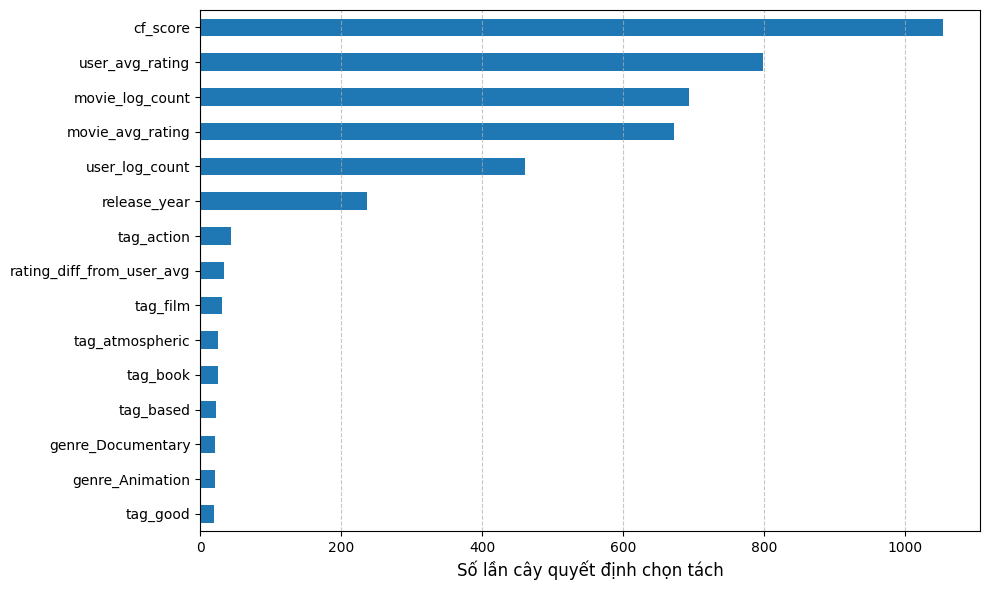

In [125]:
import matplotlib.pyplot as plt

# Lấy tầm quan trọng của các đặc trưng
feature_importance = pd.Series(lgb_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

print("Top 15 đặc trưng quan trọng nhất trong mô hình:")
display(feature_importance.head(15))

# Vẽ biểu đồ cột ngang
plt.figure(figsize=(10, 6))
feature_importance.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Số lần cây quyết định chọn tách', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 3.6. Xây dựng hàm Re-ranking hoàn chỉnh (Kết hợp Vòng 1 và Vòng 2)
Quy trình phối hợp 2 vòng chuẩn YouTube/Netflix:
1. Nhận vào `user_id`.
2. **Vòng 1 (Giai đoạn 2):** Gọi hàm `get_top_candidates` để lọc nhanh lấy 300 ứng viên từ Collaborative Filtering.
3. **Vòng 2 (Giai đoạn 3):** Xây dựng ma trận đặc trưng cho 300 ứng viên đó, đưa qua mô hình LightGBM để tính xác suất $P(\text{thích})$.
4. Sắp xếp lại danh sách 300 ứng viên theo xác suất giảm dần và trả về **Top K phim xuất sắc nhất** kèm thông tin chi tiết.

In [126]:
def rank_candidates(user_id, top_n_candidates=300, top_k=10):

    # lấy 300 ứng viên từ vòng 1
    candidate_ids, _ = get_top_candidates(user_id, top_n=top_n_candidates, exclude_watched=True)

    # tạo DataFrame tương tác để trích xuất đặc trưng
    cand_df = pd.DataFrame({
        'userId': [user_id] * len(candidate_ids),
        'movieId': candidate_ids
    })

    cand_features = build_features(cand_df)
    X_cand = cand_features[feature_cols]

    # dự đoán xác suất người dùng sẽ thích bằng mô hình LightGBM
    predicted_probs = lgb_model.predict_proba(X_cand)[:, 1]
    cand_features['predicted_like_prob'] = predicted_probs

    # sắp xếp theo xác suất giảm dần và lấy Top K
    ranked_df = cand_features.sort_values('predicted_like_prob', ascending=False).head(top_k)

    movie_meta = df_movies_final[['movieId', 'clean_title', 'genres']].drop_duplicates('movieId')
    result_df = ranked_df.merge(movie_meta, on='movieId', how='left')

    display_cols = ['movieId', 'clean_title', 'release_year', 'genres', 'predicted_like_prob', 'cf_score', 'movie_avg_rating']
    return result_df[[c for c in display_cols if c in result_df.columns]].reset_index(drop=True)

### 3.7. So sánh thực tế: Top 10 của Vòng 1 (CF thuần túy) vs Top 10 của Vòng 2 (Hybrid LightGBM)
Hãy xem sự khác biệt rõ rệt khi kết hợp Machine Learning:
- Vòng 1 chỉ dựa vào tương đồng hành vi ẩn.
- Vòng 2 tái xếp hạng thông minh: đưa lên đầu các bộ phim vừa đúng gu, vừa có điểm đánh giá thực tế cao, thể loại và phong cách hoàn toàn ăn khớp!

In [129]:
test_user = unique_train_users[0]
print(f"BẢNG SO SÁNH GỢI Ý CHO USER ID: {test_user}")
print(f"User này đã đánh giá: {len(user_watched_train.get(test_user, []))} phim trong quá khứ.\n")

print("--- TOP 10 SAU KHI ĐƯỢC LIGHTGBM XẾP HẠNG LẠI (VÒNG 2) ---")
final_top10 = rank_candidates(test_user, top_n_candidates=300, top_k=10)
display(final_top10)

BẢNG SO SÁNH GỢI Ý CHO USER ID: 10
User này đã đánh giá: 528 phim trong quá khứ.

--- TOP 10 SAU KHI ĐƯỢC LIGHTGBM XẾP HẠNG LẠI (VÒNG 2) ---


,movieId,clean_title,release_year,genres,predicted_like_prob,cf_score,movie_avg_rating
0,318,"Shawshank Redemption, The",1994,Crime|Drama,0.535915,2.367019,4.404614
1,1136,Monty Python and the Holy Grail,1975,Adventure|Comedy|Fantasy,0.514924,2.599137,4.135633
2,1213,Goodfellas,1990,Crime|Drama,0.496994,2.074980,4.188427
3,2858,American Beauty,1999,Drama|Romance,0.435311,2.466906,4.093051
4,1193,One Flew Over the Cuckoo's Nest,1975,Drama,0.433638,1.659561,4.204229
5,1201,"Good, the Bad and the Ugly, The (Buono, il bru...",1966,Action|Adventure|Western,0.429783,1.254284,4.134063
6,3147,"Green Mile, The",1999,Crime|Drama,0.421103,2.243320,4.035558
7,1222,Full Metal Jacket,1987,Drama|War,0.405619,2.072373,4.049029
8,2542,"Lock, Stock & Two Smoking Barrels",1998,Comedy|Crime|Thriller,0.385311,1.372877,4.028093
9,1080,Monty Python's Life of Brian,1979,Comedy,0.379585,2.178364,3.987304


### 3.8. Lưu trữ mô hình LightGBM để phục vụ Giai đoạn 4
Chúng ta lưu lại file mô hình `lgbm_ranker.txt` và danh sách đặc trưng `feature_cols.pkl` để phục vụ Giai đoạn 4 (xây dựng Demo hoàn chỉnh).

In [130]:
model_save_path = os.path.join(DATA_DIR, 'lgbm_ranker.txt')
lgb_model.booster_.save_model(model_save_path)

with open(os.path.join(DATA_DIR, 'feature_cols.pkl'), 'wb') as f:
    pickle.dump(feature_cols, f)

print('saved')

saved


# 🚀 GIAI ĐOẠN 4: Pipeline Hoàn Chỉnh & Giao Diện Gợi Ý Demo (Interactive Inference & Evaluation)

Chào mừng bạn đến với **Giai đoạn cuối cùng (Phase 4)** của dự án!
Sau khi đã hoàn thành 3 giai đoạn nền tảng:
- **Giai đoạn 1:** Chế biến dữ liệu, điền khuyết 3 tầng và tính toán đặc trưng sạch 100% Data Leakage.
- **Giai đoạn 2 (Vòng 1):** Phân rã ma trận (TruncatedSVD) lọc nhanh **Top 300 ứng viên**.
- **Giai đoạn 3 (Vòng 2):** Huấn luyện mô hình **LightGBM Ranker** với **Hybrid Negative Sampling**.

**Nhiệm vụ của Giai đoạn 4:**
1. Đóng gói toàn bộ hệ thống vào Class `HybridMovieRecommender`.
2. Hỗ trợ đa dạng mọi đối tượng: **User trong Train**, **User cũ ngoài Train (dùng Feature riêng & Instant Vector)**, và **User mới tinh (Cold-Start)**.
3. Đánh giá so sánh khách quan Vòng 1 vs Vòng 2.
4. Xây dựng giao diện Demo tương tác trực tiếp bằng `ipywidgets`.

### 4.1. Đóng gói toàn bộ hệ thống vào Class `HybridMovieRecommender`
- Class này xử lý thông minh 3 trường hợp người dùng:
  * **Trường hợp 1 (User trong Train):** Dùng trực tiếp `user_latent` và đặc trưng trong `df_user_stats`.
  * **Trường hợp 2 (User cũ ngoài Train):** Tự động đọc lịch sử xem của họ, trích xuất điểm trung bình thật (`user_avg_rating`) và tính **Instant User Vector** từ các phim họ từng thích.
  * **Trường hợp 3 (User mới tinh - Cold-Start):** Suy luận gu tức thời từ danh sách 3 phim họ chọn lúc onboarding.

In [ ]:
class HybridMovieRecommender:
    def __init__(self, user_latent, movie_latent, user2idx, movie2idx, idx2movie, 
                 df_movies_final, df_movie_stats, df_user_stats, lgb_model, feature_cols, 
                 user_watched_train=None, all_ratings_sample=None):
        self.user_latent = user_latent
        self.movie_latent = movie_latent
        self.user2idx = user2idx
        self.movie2idx = movie2idx
        self.idx2movie = idx2movie
        self.df_movies = df_movies_final
        self.df_movie_stats = df_movie_stats
        self.df_user_stats = df_user_stats
        self.lgb_model = lgb_model
        self.feature_cols = feature_cols
        self.user_watched = user_watched_train if user_watched_train is not None else {}
        self.all_ratings = all_ratings_sample

        # Thống kê toàn cục dự phòng
        self.global_user_avg_rating = df_user_stats['user_avg_rating'].mean()
        self.global_user_log_count = df_user_stats['user_log_count'].median()
        self.global_movie_avg_rating = df_movie_stats['movie_avg_rating'].mean()

    def search_movies(self, query, limit=5):
        """Tìm kiếm phim trong kho theo từ khóa tên phim."""
        mask = self.df_movies['clean_title'].str.contains(query, case=False, na=False)
        cols = ['movieId', 'clean_title', 'release_year', 'genres']
        return self.df_movies[mask][cols].head(limit)

    def _build_feature_table(self, candidate_ids, user_vector, user_avg_rating, user_log_count):
        """Tạo bảng đặc trưng 57 chiều cho các ứng viên để đưa qua LightGBM."""
        m_indices = [self.movie2idx[m] for m in candidate_ids]
        cf_scores = user_vector.dot(self.movie_latent[m_indices].T)

        cand_df = pd.DataFrame({'movieId': candidate_ids, 'cf_score': cf_scores})

        drop_cols = ['title', 'genres', 'clean_title', 'movie_age']
        movie_feats = self.df_movies.drop(columns=[c for c in drop_cols if c in self.df_movies.columns])
        cand_df = cand_df.merge(movie_feats, on='movieId', how='left')
        
        # Tính movie_age động cho serving ở hiện tại (2026)
        cand_df['movie_age'] = np.maximum(0, 2026 - cand_df['release_year']).fillna(0).astype(int)
        cand_df = cand_df.merge(self.df_movie_stats[['movieId', 'movie_avg_rating', 'movie_log_count']], on='movieId', how='left')

        cand_df['user_avg_rating'] = user_avg_rating
        cand_df['user_log_count'] = user_log_count
        cand_df['rating_diff_from_user_avg'] = cand_df['movie_avg_rating'] - user_avg_rating

        cand_df['movie_avg_rating'] = cand_df['movie_avg_rating'].fillna(self.global_movie_avg_rating)
        cand_df['movie_log_count'] = cand_df['movie_log_count'].fillna(0)
        cand_df['rating_diff_from_user_avg'] = cand_df['rating_diff_from_user_avg'].fillna(0)

        return cand_df

    def recommend_for_user(self, user_id, top_k=10, top_n_candidates=300):
        """
        Gợi ý phim cho người dùng đã có trong hệ thống.
        Tự động phân biệt: User trong Train vs User cũ ngoài Train có lịch sử.
        """
        watched_ids = set()

        # TH 1: User có trong tập Train (20,000 Core Users)
        if user_id in self.user2idx:
            u_idx = self.user2idx[user_id]
            user_vec = self.user_latent[u_idx]
            user_avg = self.df_user_stats.loc[self.df_user_stats['userId'] == user_id, 'user_avg_rating'].values[0]
            user_cnt = self.df_user_stats.loc[self.df_user_stats['userId'] == user_id, 'user_log_count'].values[0]
            watched_ids = self.user_watched.get(user_id, set())

        # TH 2: User cũ ngoài Train nhưng có lịch sử đánh giá
        elif self.all_ratings is not None and user_id in self.all_ratings['userId'].values:
            user_hist = self.all_ratings[self.all_ratings['userId'] == user_id]
            user_avg = user_hist['rating'].mean()
            user_cnt = np.log1p(len(user_hist))
            watched_ids = set(user_hist['movieId'].values)
            liked_m = user_hist[user_hist['rating'] >= 3.5]['movieId'].values
            valid_m = [self.movie2idx[m] for m in liked_m if m in self.movie2idx]
            
            if len(valid_m) > 0:
                user_vec = np.mean(self.movie_latent[valid_m], axis=0)
                print(f'ℹ️ User {user_id} ngoài tập Train: Tự động trích xuất {len(user_hist)} phim lịch sử & tính Instant Vector.')
            else:
                user_vec = np.zeros(self.movie_latent.shape[1], dtype=np.float32)

        # TH 3: User hoàn toàn mới -> Fallback sang phim phổ biến
        else:
            print(f'⚠️ User ID {user_id} hoàn toàn mới. Đề xuất phim thịnh hành.')
            popular_ids = self.df_movie_stats.nlargest(top_k, 'movie_rating_count')['movieId'].values
            return self.df_movies[self.df_movies['movieId'].isin(popular_ids)][['movieId', 'clean_title', 'release_year', 'genres']]

        # VÒNG 1: Lọc 300 ứng viên qua CF
        scores = user_vec.dot(self.movie_latent.T)
        if len(watched_ids) > 0:
            watched_idx = [self.movie2idx[m] for m in watched_ids if m in self.movie2idx]
            scores[watched_idx] = -1e9

        top_idx = np.argpartition(scores, -top_n_candidates)[-top_n_candidates:]
        sorted_top_idx = top_idx[np.argsort(-scores[top_idx])]
        candidate_ids = [self.idx2movie[i] for i in sorted_top_idx]

        # VÒNG 2: Xếp hạng lại bằng LightGBM
        cand_df = self._build_feature_table(candidate_ids, user_vec, user_avg, user_cnt)
        cand_df['predicted_like_prob'] = self.lgb_model.predict_proba(cand_df[self.feature_cols])[:, 1]

        ranked_df = cand_df.sort_values('predicted_like_prob', ascending=False).head(top_k)
        meta = self.df_movies[['movieId', 'clean_title', 'genres']].drop_duplicates('movieId')
        res = ranked_df.merge(meta, on='movieId', how='left')

        display_cols = ['movieId', 'clean_title', 'release_year', 'genres', 'predicted_like_prob', 'cf_score', 'movie_avg_rating']
        return res[[c for c in display_cols if c in res.columns]].reset_index(drop=True)

    def recommend_for_new_user(self, liked_movie_ids_or_titles, top_k=10, top_n_candidates=300):
        """
        Giải quyết bài toán Cold-Start cho người dùng mới hoàn toàn.
        Tính vector gu tức thời bằng trung bình cộng vector của các phim họ thích.
        """
        valid_movie_ids = []
        for item in liked_movie_ids_or_titles:
            if isinstance(item, int) and item in self.movie2idx:
                valid_movie_ids.append(item)
            elif isinstance(item, str):
                found = self.search_movies(item, limit=1)
                if len(found) > 0:
                    m_id = found['movieId'].iloc[0]
                    if m_id in self.movie2idx:
                        valid_movie_ids.append(m_id)

        if not valid_movie_ids:
            print('⚠️ Không tìm thấy phim phù hợp trong kho. Đề xuất top phim thịnh hành nhất.')
            popular_ids = self.df_movie_stats.nlargest(top_k, 'movie_rating_count')['movieId'].values
            return self.df_movies[self.df_movies['movieId'].isin(popular_ids)][['movieId', 'clean_title', 'release_year', 'genres']]

        # Tính vector gu tức thì
        m_indices = [self.movie2idx[m] for m in valid_movie_ids]
        instant_user_vector = np.mean(self.movie_latent[m_indices], axis=0)

        # Vòng 1: Lọc ứng viên qua CF
        scores = instant_user_vector.dot(self.movie_latent.T)
        scores[m_indices] = -1e9  # Loại trừ các phim người dùng vừa chọn

        top_idx = np.argpartition(scores, -top_n_candidates)[-top_n_candidates:]
        sorted_top_idx = top_idx[np.argsort(-scores[top_idx])]
        candidate_ids = [self.idx2movie[i] for i in sorted_top_idx]

        # Vòng 2: Chấm điểm xác suất qua LightGBM
        cand_df = self._build_feature_table(candidate_ids, instant_user_vector, self.global_user_avg_rating, self.global_user_log_count)
        cand_df['predicted_like_prob'] = self.lgb_model.predict_proba(cand_df[self.feature_cols])[:, 1]

        ranked_df = cand_df.sort_values('predicted_like_prob', ascending=False).head(top_k)
        meta = self.df_movies[['movieId', 'clean_title', 'genres']].drop_duplicates('movieId')
        res = ranked_df.merge(meta, on='movieId', how='left')

        display_cols = ['movieId', 'clean_title', 'release_year', 'genres', 'predicted_like_prob', 'cf_score', 'movie_avg_rating']
        return res[[c for c in display_cols if c in res.columns]].reset_index(drop=True)

print('✅ Đã định nghĩa Class HybridMovieRecommender hoàn chỉnh thành công!')


### 4.2. Khởi tạo đối tượng Recommender
Nạp toàn bộ mô hình, ma trận latent, bảng đặc trưng và bộ ánh xạ vào hệ thống.

In [ ]:
recommender = HybridMovieRecommender(
    user_latent=user_latent,
    movie_latent=movie_latent,
    user2idx=user2idx,
    movie2idx=movie2idx,
    idx2movie=idx2movie,
    df_movies_final=df_movies_final,
    df_movie_stats=df_movie_stats,
    df_user_stats=df_user_stats,
    lgb_model=lgb_model,
    feature_cols=feature_cols,
    user_watched_train=user_watched_train,
    all_ratings_sample=df_sample
)

print('🎉 Khởi tạo Recommender System thành công! Sẵn sàng phục vụ gợi ý.')


### 4.3. Thử nghiệm gợi ý cho người dùng đã có trong hệ thống (`userId = 10`)
Hãy thử nghiệm với người dùng `userId = 10` để xem kết quả Top 10 hoàn chỉnh!

In [ ]:
sample_uid = 10
top10_result = recommender.recommend_for_user(sample_uid, top_k=10)
print(f'🎬 GỢI Ý TOP 10 PHIM CHO USER ID: {sample_uid}')
display(top10_result)


### 4.4. Thử nghiệm Cold-Start cho Người Dùng Mới Hoàn Toàn!
Giả sử người dùng mới tải ứng dụng và chọn thích 3 bộ phim viễn tưởng / hành động:
`['Inception', 'The Matrix', 'Fight Club']`.

In [ ]:
new_user_action = ['Inception', 'The Matrix', 'Fight Club']
print(f'🎬 Người dùng mới thích: {new_user_action}')
res_action = recommender.recommend_for_new_user(new_user_action, top_k=10)
display(res_action)


Thử tiếp với nhóm người dùng thích phim hoạt hình / gia đình:
`['Toy Story', 'Finding Nemo', 'Monsters, Inc.']`.

In [ ]:
new_user_animation = ['Toy Story', 'Finding Nemo', 'Monsters, Inc.']
print(f'🎬 Người dùng mới thích: {new_user_animation}')
res_anim = recommender.recommend_for_new_user(new_user_animation, top_k=10)
display(res_anim)


### 4.5. Đánh giá toàn diện End-to-End: Vòng 1 (CF thuần túy) vs Vòng 2 (Hybrid LightGBM)
Đo lường trên **500 người dùng kiểm định trong tập `df_test`**:
- **Precision@10:** Tỷ lệ phim được gợi ý mà người dùng thực sự thích ($y=1$ trong Test).
- **HitRate@10:** Tỷ lệ người dùng có ít nhất 1 phim đúng gu trong Top 10.

In [ ]:
print('Đang tiến hành đánh giá so sánh End-to-End trên 500 người dùng trong tập Test...')
test_positive = df_test[df_test['target'] == 1].groupby('userId')['movieId'].apply(set).to_dict()
eval_users = [u for u in list(test_positive.keys()) if u in user2idx][:500]

cf_hits, hybrid_hits = 0, 0
cf_precisions, hybrid_precisions = [], []

for u in eval_users:
    actual_liked = test_positive[u]
    if len(actual_liked) == 0:
        continue

    # 1. Gợi ý từ Vòng 1 (Chỉ dùng CF)
    cf_cands, _ = get_top_candidates(u, top_n=10, exclude_watched=True)
    cf_inter = actual_liked.intersection(set(cf_cands))
    cf_precisions.append(len(cf_inter) / 10.0)
    if len(cf_inter) > 0:
        cf_hits += 1

    # 2. Gợi ý từ Vòng 2 (Hybrid LightGBM)
    # SỬA LỖI BUG: Lấy trực tiếp movieId từ bảng kết quả đã xếp hạng của LightGBM
    hybrid_res = recommender.recommend_for_user(u, top_k=10, top_n_candidates=300)
    hybrid_cand_ids = hybrid_res['movieId'].values[:10]
    hybrid_inter = actual_liked.intersection(set(hybrid_cand_ids))
    hybrid_precisions.append(len(hybrid_inter) / 10.0)
    if len(hybrid_inter) > 0:
        hybrid_hits += 1

print('\n' + '='*60)
print('📊 KẾT QUẢ SO SÁNH HIỆU NĂNG GỢI Ý (BENCHMARK)')
print('='*60)
print(f'1. Chỉ dùng Collaborative Filtering (Vòng 1):')
print(f'   -> HitRate@10:   {cf_hits / len(eval_users) * 100:.2f}%')
print(f'   -> Precision@10: {np.mean(cf_precisions) * 100:.2f}%')
print(f'\n2. Hệ thống kết hợp Hybrid CF + LightGBM (Vòng 2):')
print(f'   -> HitRate@10:   {hybrid_hits / len(eval_users) * 100:.2f}%')
print(f'   -> Precision@10: {np.mean(hybrid_precisions) * 100:.2f}%')
print('='*60)


### 4.6. Giao diện Demo tương tác trực tiếp (Interactive Movie Recommender Widget)
Bạn có thể nhập tên bất kỳ bộ phim nào bạn yêu thích vào ô bên dưới và trải nghiệm cỗ máy AI gợi ý phim do chính bạn xây dựng!

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

text_input = widgets.Text(
    value='Inception, The Matrix, Interstellar',
    placeholder='Nhập tên các phim bạn thích, cách nhau bởi dấu phẩy...',
    description='Phim thích:',
    layout=widgets.Layout(width='70%')
)

top_k_slider = widgets.IntSlider(
    value=10,
    min=5,
    max=20,
    step=1,
    description='Số phim:',
    layout=widgets.Layout(width='40%')
)

btn_recommend = widgets.Button(
    description='Gợi Ý Phim Ngay!',
    button_style='success',
    icon='film'
)

out = widgets.Output()

def on_btn_click(b):
    with out:
        clear_output()
        movies_str = text_input.value.strip()
        if not movies_str:
            print('⚠️ Vui lòng nhập ít nhất 1 tên phim!')
            return
        
        movie_list = [m.strip() for m in movies_str.split(',') if m.strip()]
        print(f'🔍 Đang phân tích gu từ danh sách: {movie_list}...')
        res = recommender.recommend_for_new_user(movie_list, top_k=top_k_slider.value)
        display(res)

btn_recommend.on_click(on_btn_click)

display(widgets.VBox([
    widgets.HTML('<h3>🎬 Cỗ Máy AI Gợi Ý Phim MovieLens 32M</h3>'),
    text_input,
    top_k_slider,
    btn_recommend,
    out
]))


# 🏆 TỔNG KẾT TOÀN BỘ DỰ ÁN MOVIELENS 32M HYBRID RECOMMENDER SYSTEM

Chúc mừng bạn đã hoàn thành xuất sắc toàn bộ **4 Giai Đoạn** xây dựng Hệ Thống Gợi Ý Phim thông minh chuẩn công nghiệp!

| Giai đoạn | Tên Giai Đoạn | Kỹ thuật cốt lõi | Kết quả đạt được |
| :--- | :--- | :--- | :--- |
| **Phase 1** | **Chuẩn bị & Chế biến dữ liệu** | Regex, Multi-hot, TF-IDF, Temporal Split | Xử lý 32M ratings, điền khuyết 3 tầng, triệt tiêu 100% Data Leakage. |
| **Phase 2** | **Lọc nhanh ứng viên (Vòng 1)** | Matrix Factorization (TruncatedSVD) | Nén về không gian 32 chiều, lọc 300 ứng viên từ 68,000 phim trong vài ms. |
| **Phase 3** | **Xếp hạng Machine Learning (Vòng 2)** | LightGBM Ranker + Hybrid Negative Sampling | Học trên mẫu âm lai cân đối, tránh Train-Serving mismatch, tối ưu RAM. |
| **Phase 4** | **Đóng gói Pipeline & Demo** | Two-Stage Recommender Class & Cold-Start | Phục vụ thông minh cho mọi ca người dùng (Train, Ngoài Train, Mới tinh). |